In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
CURRENT_FOLDER = Path.cwd()

if CURRENT_FOLDER.name == "notebooks":
    PROJECT_ROOT = CURRENT_FOLDER.parent
else:
    PROJECT_ROOT = CURRENT_FOLDER

DATA_FILE = (
    PROJECT_ROOT
    / "dataset"
    / "air_quality_merged_clean.csv"
)

print("Dataset path:", DATA_FILE)

Dataset path: c:\Users\harsh bhuvad\OneDrive\Desktop\ML_Project\Mulitiple_Linear_Regression\dataset\air_quality_merged_clean.csv


In [4]:
data = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [5]:
display(data.head())

,pm10,no2,so2,co,ozone,humidity,wind_speed,pm25
0,59.48,3.80,9.03,4.90,13.61,68.53,1.53,12.38
1,497.25,13.18,4.78,5.53,0.55,81.75,0.75,359.00
2,139.43,4.93,7.52,0.27,78.84,41.30,0.72,32.90
3,224.83,19.79,14.68,0.51,32.52,70.78,0.59,96.75
4,16.75,12.88,3.48,0.73,6.07,78.50,1.20,3.00


In [6]:
display(data.tail())

,pm10,no2,so2,co,ozone,humidity,wind_speed,pm25
338027,464.09,10.66,6.17,1.84,2.04,62.20,0.26,271.09
338028,52.75,13.83,13.10,0.21,3.18,42.34,7.52,39.38
338029,96.25,10.15,26.95,0.32,18.28,95.00,1.90,62.25
338030,113.40,9.38,1.43,0.92,40.55,64.42,2.00,52.91
338031,92.58,25.80,8.46,0.45,15.84,82.81,0.71,47.27


In [7]:
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

Rows: 338032
Columns: 8


In [8]:
print(data.columns.tolist())

['pm10', 'no2', 'so2', 'co', 'ozone', 'humidity', 'wind_speed', 'pm25']


In [9]:
print(data.columns)

Index(['pm10', 'no2', 'so2', 'co', 'ozone', 'humidity', 'wind_speed', 'pm25'], dtype='str')


In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 338032 entries, 0 to 338031
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   pm10        338032 non-null  float64
 1   no2         338032 non-null  float64
 2   so2         338032 non-null  float64
 3   co          338032 non-null  float64
 4   ozone       338032 non-null  float64
 5   humidity    338032 non-null  float64
 6   wind_speed  338032 non-null  float64
 7   pm25        338032 non-null  float64
dtypes: float64(8)
memory usage: 20.6 MB


In [11]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 0


In [12]:
display(data.describe().T)

,count,mean,std,min,25%,50%,75%,max
pm10,338032.0,127.789292,111.208794,0.02,53.33,94.75,164.83,913.75
no2,338032.0,26.539350,27.585195,0.01,9.00,17.40,34.27,253.40
so2,338032.0,12.657468,13.606650,0.01,4.46,8.48,16.00,151.00
co,338032.0,0.877808,0.789123,0.00,0.40,0.68,1.10,8.00
ozone,338032.0,31.262506,31.821531,0.01,8.80,19.89,42.67,187.43
humidity,338032.0,62.950969,22.913440,0.01,46.00,65.50,81.57,99.99
wind_speed,338032.0,1.235962,1.925066,0.01,0.40,0.79,1.41,34.09
pm25,338032.0,59.463780,60.035713,0.01,22.33,41.12,74.22,601.25


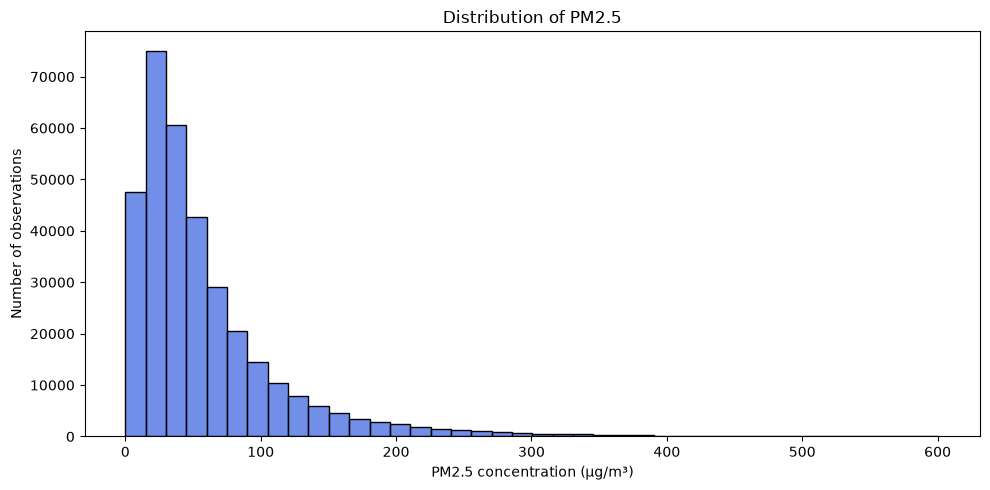

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=data,
    x="pm25",
    bins=40,
    color="royalblue",
)

plt.title("Distribution of PM2.5")
plt.xlabel("PM2.5 concentration (µg/m³)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

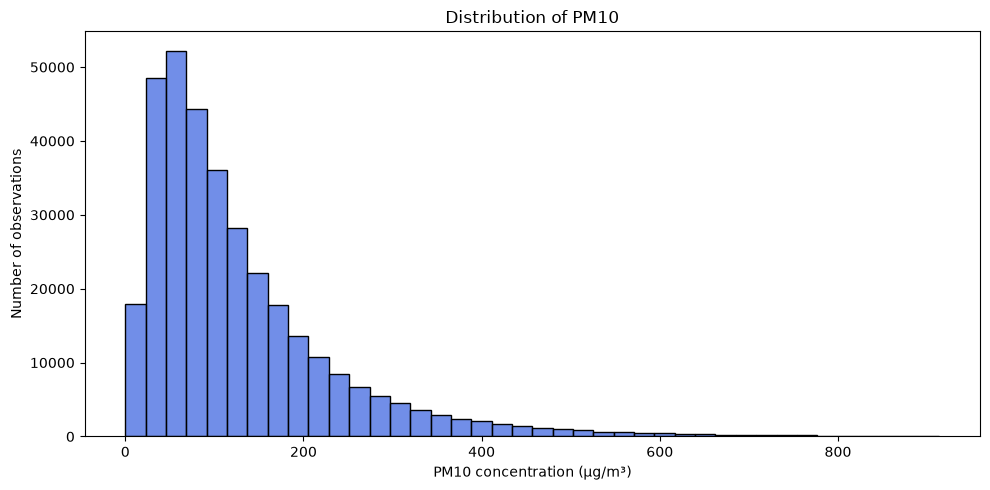

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=data,
    x="pm10",
    bins=40,
    color="royalblue",
)

plt.title("Distribution of PM10")
plt.xlabel("PM10 concentration (µg/m³)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

In [15]:
min_value = data["pm25"].min()
max_value = data["pm25"].max()

print("Minimum:", min_value)
print("Maximum:", max_value)

bin_width = (max_value - min_value) / 40

print("Bin width:", bin_width)

Minimum: 0.01
Maximum: 601.25
Bin width: 15.031


In [16]:
counts, bin_edges = np.histogram(
    data["pm25"],
    bins=40
)

print(bin_edges)

[1.00000e-02 1.50410e+01 3.00720e+01 4.51030e+01 6.01340e+01 7.51650e+01
 9.01960e+01 1.05227e+02 1.20258e+02 1.35289e+02 1.50320e+02 1.65351e+02
 1.80382e+02 1.95413e+02 2.10444e+02 2.25475e+02 2.40506e+02 2.55537e+02
 2.70568e+02 2.85599e+02 3.00630e+02 3.15661e+02 3.30692e+02 3.45723e+02
 3.60754e+02 3.75785e+02 3.90816e+02 4.05847e+02 4.20878e+02 4.35909e+02
 4.50940e+02 4.65971e+02 4.81002e+02 4.96033e+02 5.11064e+02 5.26095e+02
 5.41126e+02 5.56157e+02 5.71188e+02 5.86219e+02 6.01250e+02]


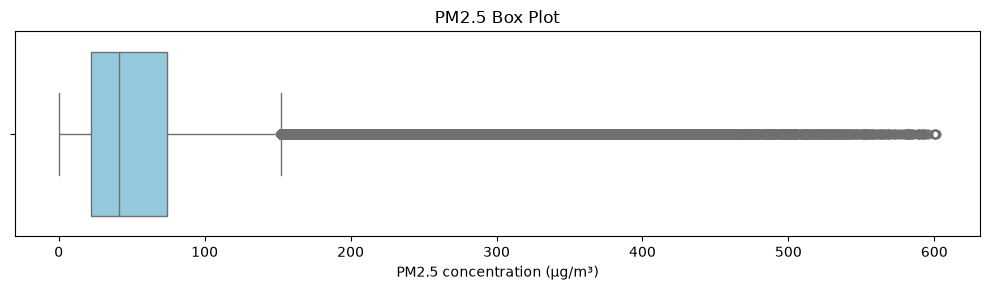

In [17]:
plt.figure(figsize=(10, 3))

sns.boxplot(
    data=data,
    x="pm25",
    color="skyblue",
)

plt.title("PM2.5 Box Plot")
plt.xlabel("PM2.5 concentration (µg/m³)")
plt.tight_layout()
plt.show()

In [18]:
PLOT_SIZE = min(
    50_000,
    len(data),
)

plot_data = data.sample(
    n=PLOT_SIZE,
    random_state=42,
)

[[<Axes: > <Axes: > <Axes: > <Axes: >]
 [<Axes: > <Axes: > <Axes: > <Axes: >]]
[<Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]


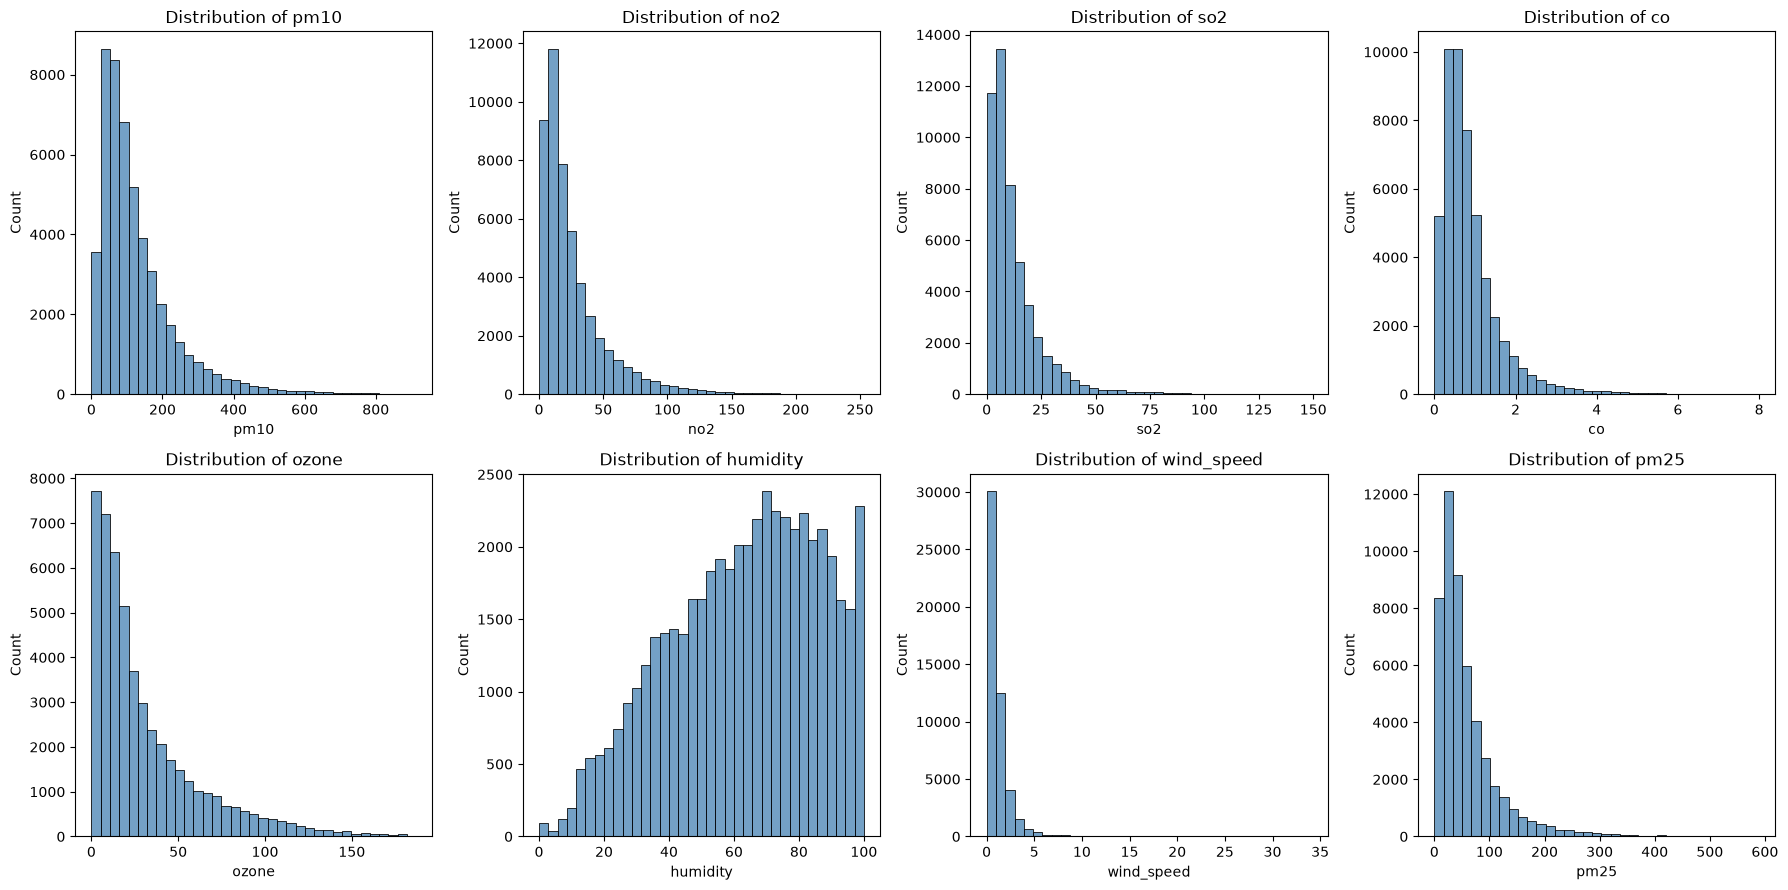

In [19]:
columns = data.columns.tolist()

figure, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(18, 9),
)

print(axes)
axes = axes.flatten()
print(axes)
for column, axis in zip(columns, axes):
    sns.histplot(
        data=plot_data,
        x=column,
        bins=35,
        ax=axis,
        color="steelblue",
    )

    axis.set_title(
        f"Distribution of {column}"
    )

plt.tight_layout()
plt.show()

In [20]:
correlation_matrix = data.corr()

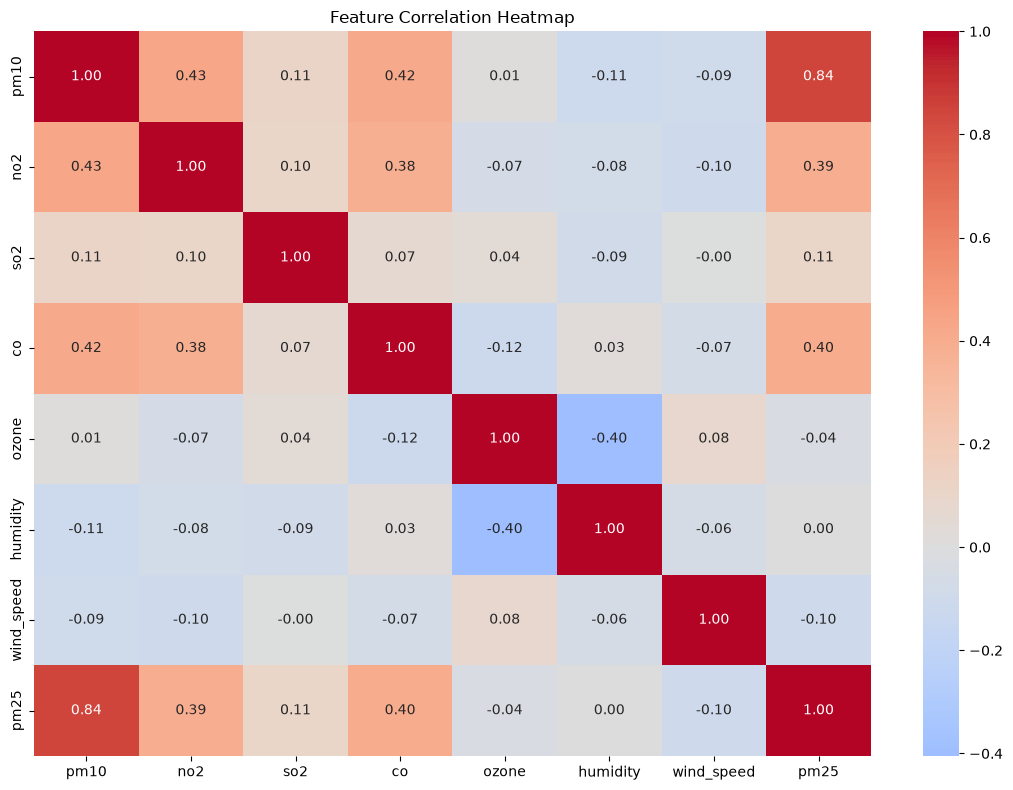

In [21]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()